In [1]:
from pathlib import Path

import numpy as np
import lightning as L
import matplotlib.pyplot as plt
from matplotlib.colors import CenteredNorm
import torch
import torchmetrics
from tqdm import tqdm

from minerva.data.data_modules.base import MinervaDataModule
from minerva.data.datasets.base import SimpleDataset
from minerva.models.nets.image.deeplabv3 import DeepLabV3
from minerva.transforms.transform import Repeat, CastTo, Unsqueeze, PadCrop, TransformPipeline

from utils.data import NumpyPatchReader

## Create the Data Module

In [2]:
root_data_dir = Path("../../../../data/processed/faults/thebe/partition_method_predefined/")
seed = 42

In [3]:
norm = None # "min-max" "z-score" # Patches can me normalized using 'min-max' or 'z-score' 
                                    # by using info stored in a metadata file with statistics for the whole panel
patch_size = (96, 96) # as Test Split is stored as panels and not patches, we pass the patch size
patch_stride = (48, 48) # and patch_stride here to tell the reader to extract the patches on the fly

###########################
# Train dataset
###########################
train_data_reader = NumpyPatchReader(
    path=root_data_dir / "train" / "data",
    norm=norm, 
)
train_label_reader = NumpyPatchReader(
    path=root_data_dir / "train" / "label",
)
train_data_transforms = TransformPipeline(
    [
        Unsqueeze(0),
        Repeat(axis=0, n_repetitions=3),
        CastTo("float32"),
    ]
)

train_label_transforms = TransformPipeline(
    [
        CastTo("int64"),
    ]
)

train_dataset = SimpleDataset(
    readers=[train_data_reader, train_label_reader],
    transforms=[train_data_transforms, train_label_transforms],
)

###########################
# Validation dataset
###########################
val_data_reader = NumpyPatchReader(
    path=root_data_dir / "val" / "data",
    norm=norm,
)
val_label_reader = NumpyPatchReader(
    path=root_data_dir / "val" / "label",
)
val_data_transforms = TransformPipeline(
    [
        Unsqueeze(0),
        Repeat(axis=0, n_repetitions=3),
        CastTo("float32"),
    ]
)
val_label_transforms = TransformPipeline(
    [
        CastTo("int64"),
    ]
)

val_dataset = SimpleDataset(
    readers=[val_data_reader, val_label_reader],
    transforms=[val_data_transforms, val_label_transforms],
)


test_data_reader = NumpyPatchReader(
    path=root_data_dir / "test" / "data",
    patch_size=patch_size,   
    patch_stride=patch_stride, 
    norm=norm,
)
test_label_reader = NumpyPatchReader(
    path=root_data_dir / "test" / "label",
    patch_size=patch_size,
    patch_stride=patch_stride,
)
test_data_transforms = TransformPipeline(
    [Unsqueeze(0), Repeat(axis=0, n_repetitions=3), CastTo("float32")]
)  # Transforms to first reader (data)
test_label_transforms = TransformPipeline([CastTo("int64")])

test_dataset = SimpleDataset(
    readers=[test_data_reader, test_label_reader],
    transforms=[test_data_transforms, test_label_transforms],
)

In [4]:
len(test_dataset)

325992

In [5]:
len(train_dataset)

181029

In [6]:
len(val_dataset)

64317

In [7]:
train_x, train_y = train_dataset[0]
print(f"Train sample shapes: {train_x.shape} (dtype: {train_x.dtype}), Label Shape: {train_y.shape} (dtype: {train_y.dtype})")

val_x, val_y = val_dataset[0]
print(f"Validation sample shapes: {val_x.shape} (dtype: {val_x.dtype}), Label Shape: {val_y.shape} (dtype: {val_y.dtype})")

test_x, test_y = test_dataset[0]
print(f"Test sample shapes: {test_x.shape} (dtype: {test_x.dtype}), Label Shape: {test_y.shape} (dtype: {test_y.dtype})")

Train sample shapes: (3, 96, 96) (dtype: float32), Label Shape: (96, 96) (dtype: int64)
Validation sample shapes: (3, 96, 96) (dtype: float32), Label Shape: (96, 96) (dtype: int64)
Test sample shapes: (3, 96, 96) (dtype: float32), Label Shape: (96, 96) (dtype: int64)


In [8]:
data_module = MinervaDataModule(
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    test_dataset=test_dataset,
    batch_size=128, # increase batch_size to 512 in real training
    num_workers=4,  # increase num_workers to 32
    additional_train_dataloader_kwargs={"drop_last": True},
    name="Thebe Dataset"
)

print(data_module)

                  🆔 Thebe Dataset
└── Predict Split: test
📂 Datasets:
   ├── Train Dataset:
   │      ==================================================
   │                 📂 SimpleDataset Information            
   │      ==================================================
   │      📌 Dataset Type: SimpleDataset
   │         └── Reader 0: NumpyPatchReader at '../../../../data/processed/faults/thebe/partition_method_predefined/train/data' (181029 files and 181029 patches)
   │         │     └── Transform: TransformPipeline(transforms=[Unsqueeze(axis=0), Repeat(axis=0, n_repetitions=3), CastTo(dtype=float32)])
   │         └── Reader 1: NumpyPatchReader at '../../../../data/processed/faults/thebe/partition_method_predefined/train/label' (181029 files and 181029 patches)
   │         │     └── Transform: TransformPipeline(transforms=[CastTo(dtype=int64)])
   │         │
   │         └── Total Readers: 2
   │      ==================================================
   ├── Val Dataset:
   │

### Plot a sample from the training set

In [9]:
def plot_data_label_slice(data, label, size=(12, 6), show=True):
    fig, axes = plt.subplots(1, 2, figsize=size)

    axes[0].imshow(data, cmap="seismic")
    axes[0].set_title("Seismic Data Slice")

    axes[1].imshow(label, cmap="gray", vmin=0, vmax=np.max(label))
    axes[1].set_title("Facies Label Slice")
    axes[1].colorbar = plt.colorbar(axes[1].images[0], ax=axes[1])

    plt.tight_layout()
    if show:
        plt.show()
    return fig

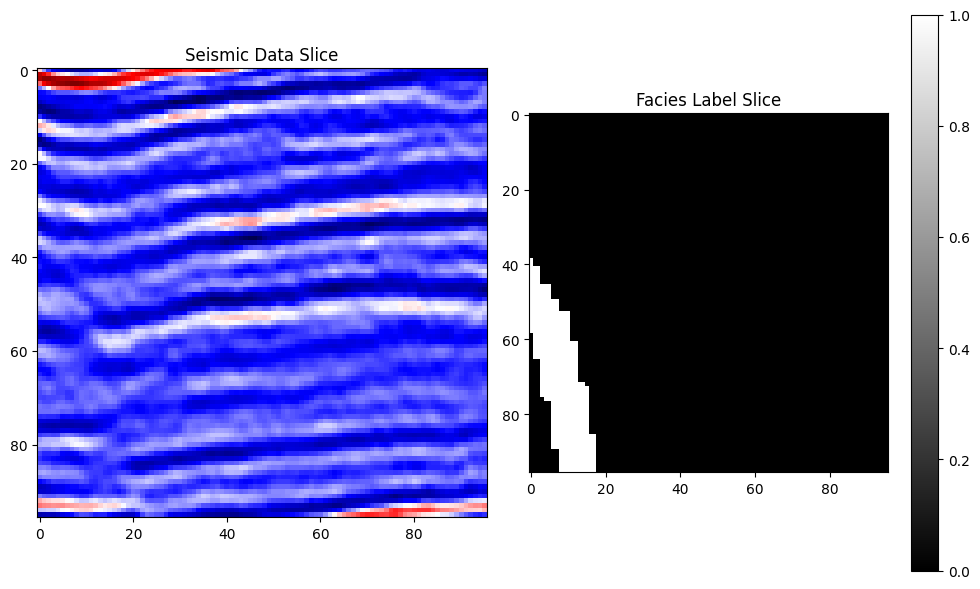

In [10]:
x, y = train_dataset[1000]
fig = plot_data_label_slice(x[0, :, :], y, size=(10, 6), show=False)
fig.show()

## Model

In [11]:
class BCEWithLogitsLossUnsqueezedTarget(torch.nn.Module):
    """
    BCEWithLogitsLoss with unsqueezed targets (Wrapper class).  
    This is needed because the model outputs a tensor of shape (B, 1, H, W) for binary segmentation,
    but the labels are of shape (B, H, W).
    Thus, we need to unsqueeze the targets to match the shape of the inputs before computing the loss.
    """
    def __init__(self):
        super().__init__()
        self.loss_fn = torch.nn.BCEWithLogitsLoss()

    def forward(self, inputs, targets):
        # Unsqueeze targets to add a channel dimension
        targets = targets.unsqueeze(1).float()  # Shape: (B, 1, H, W)
        return self.loss_fn(inputs, targets)

model = DeepLabV3(
    num_classes=1,
    loss_fn=BCEWithLogitsLossUnsqueezedTarget(),
)
model

DeepLabV3(
  (backbone): DeepLabV3Backbone(
    (RN50model): ResNet(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu)

## Trainer

In [12]:
trainer = L.Trainer(
    max_epochs=3,
    logger=False,                   # Disable logging for simplicity
    enable_checkpointing=False,     # Disable checkpointing for simplicity
    accelerator="gpu",
    devices=1,
    limit_train_batches=10,       # Run a fraction of training batches for quick testing
    limit_val_batches=10,         # Run a fraction of validation batches for quick testing
    limit_test_batches=10,        # Run a fraction of test batches for quick testing
)

trainer

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [ ]:
trainer.fit(model, data_module)

Epoch 60/99 ━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━ 143/353 0:01:55 • 0:02:36 1.35it/s v_num: 4.000 val_loss: 1.011      
                                                                                 train_loss: 0.031                 

## Calculate metrics on the test set

For this dataset, metrics are computed on the aggregated predictions for a whole test panel

In [74]:
panels_metadata = []
for data_file, label_file in zip(test_data_reader.files, test_label_reader.files):
    rows, cols = data_file.stem.split("_")
    rows, cols = int(rows), int(cols)
    row_patches = ((rows-patch_size[0])//patch_stride[0]) + 1
    col_patches = ((cols-patch_size[1])//patch_stride[1]) + 1
    patches = row_patches*col_patches
    panels_metadata.append((row_patches, col_patches, data_file, label_file))

def merge_predictions(logits, metadata):
    preds = torch.sigmoid(logits.squeeze(1)).cpu().numpy()
    patch_count = np.ones(patch_size)
    merged_predictions = []
    panels = []
    labels = []
    cur_idx = 0
    for panel in tqdm(metadata):
        
        pad_slice = tuple([ # Default padding slice
                slice(71, -72),
                slice(69, -69)
            ])
        acc = np.zeros(((panel[0]-1)*patch_stride[0] + patch_size[0], (panel[1]-1)*patch_stride[1] + patch_size[1]))
        count = np.zeros_like(acc)
        panels.append(np.load(panel[2])[pad_slice])
        labels.append(np.load(panel[3])[pad_slice])
        for i, j in np.ndindex(panel[0], panel[1]):
            sl = tuple([
                slice(i*patch_stride[0], i*patch_stride[0]+patch_size[0]),
                slice(j*patch_stride[1], j*patch_stride[1]+patch_size[1])
            ])
            acc[sl] += preds[cur_idx]
            count[sl] +=  patch_count
            cur_idx += 1
        res = (acc/count)[pad_slice]
        merged_predictions.append(res)
    
    print(cur_idx)
    print(preds.shape)
    return merged_predictions, panels, labels

In [ ]:
# Predict (takes ~25 minutes)
logits = trainer.predict(model, data_module)  # type: ignore
logits = torch.cat(logits, dim=0)  # type: ignore

In [75]:
preds, panels, labels = merge_predictions(logits, panels_metadata)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 141/141 [00:18<00:00,  7.81it/s]


325992
(325992, 96, 96)


In [76]:
preds = torch.from_numpy(np.stack(preds)).cuda()
y_true = torch.from_numpy(np.stack(labels)).cuda().long()
y_pred = (preds > 0.5).long()
inputs = torch.from_numpy(np.stack(panels)).cuda()

In [80]:
# Balanced Accuracy = (Sensitivity + Specificity) / 2
recall_metric = torchmetrics.classification.BinaryRecall().to(y_pred.device)
specificity_metric = torchmetrics.classification.BinarySpecificity().to(y_pred.device)

# Pixel Accuracy with torchmetrics
pixel_acc_metric = torchmetrics.classification.BinaryAccuracy().to(y_pred.device)
pixel_accuracy = pixel_acc_metric(y_pred, y_true)


sensitivity = recall_metric(y_pred, y_true)
specificity = specificity_metric(y_pred, y_true)
balanced_accuracy = (sensitivity + specificity) / 2

print(f"Sensitivity (Recall):       {sensitivity.item():.4f}")
print(f"Specificity:                {specificity.item():.4f}")
print(f"Balanced Accuracy:          {balanced_accuracy.item() * 100:.2f}%")
print(f"Pixel Accuracy on Test Set: {pixel_accuracy.item() * 100:.2f}%")

Sensitivity (Recall):       0.4249
Specificity:                0.9958
Balanced Accuracy:          71.03%
Pixel Accuracy on Test Set: 98.60%


### Plot a prediction from the test set

In [82]:
def plot_data_label_prediction_slice(data, label, prediction, size=(18, 24), show=True):
    fig, axes = plt.subplots(4, 1, figsize=size)

    axes[0].imshow(data, cmap="seismic", norm=CenteredNorm())
    axes[0].set_title("Seismic Data Slice")
    axes[0].colorbar = plt.colorbar(axes[0].images[0], ax=axes[0])

    axes[1].imshow(label, cmap="gray", vmin=0, vmax=np.max(label))
    axes[1].set_title("Facies Label Slice")
    axes[1].colorbar = plt.colorbar(axes[1].images[0], ax=axes[1])
    
    axes[2].imshow(prediction, cmap="gray", vmin=0, vmax=1)
    axes[2].set_title("Predicted Probs Facies Slice")
    axes[2].colorbar = plt.colorbar(axes[2].images[0], ax=axes[2])
    
    axes[3].imshow(prediction > 0.5, cmap="gray", vmin=0, vmax=1)
    axes[3].set_title("Predicted Facies Slice")
    axes[3].colorbar = plt.colorbar(axes[3].images[0], ax=axes[3])

    plt.tight_layout()
    if show:
        plt.show()
    return fig

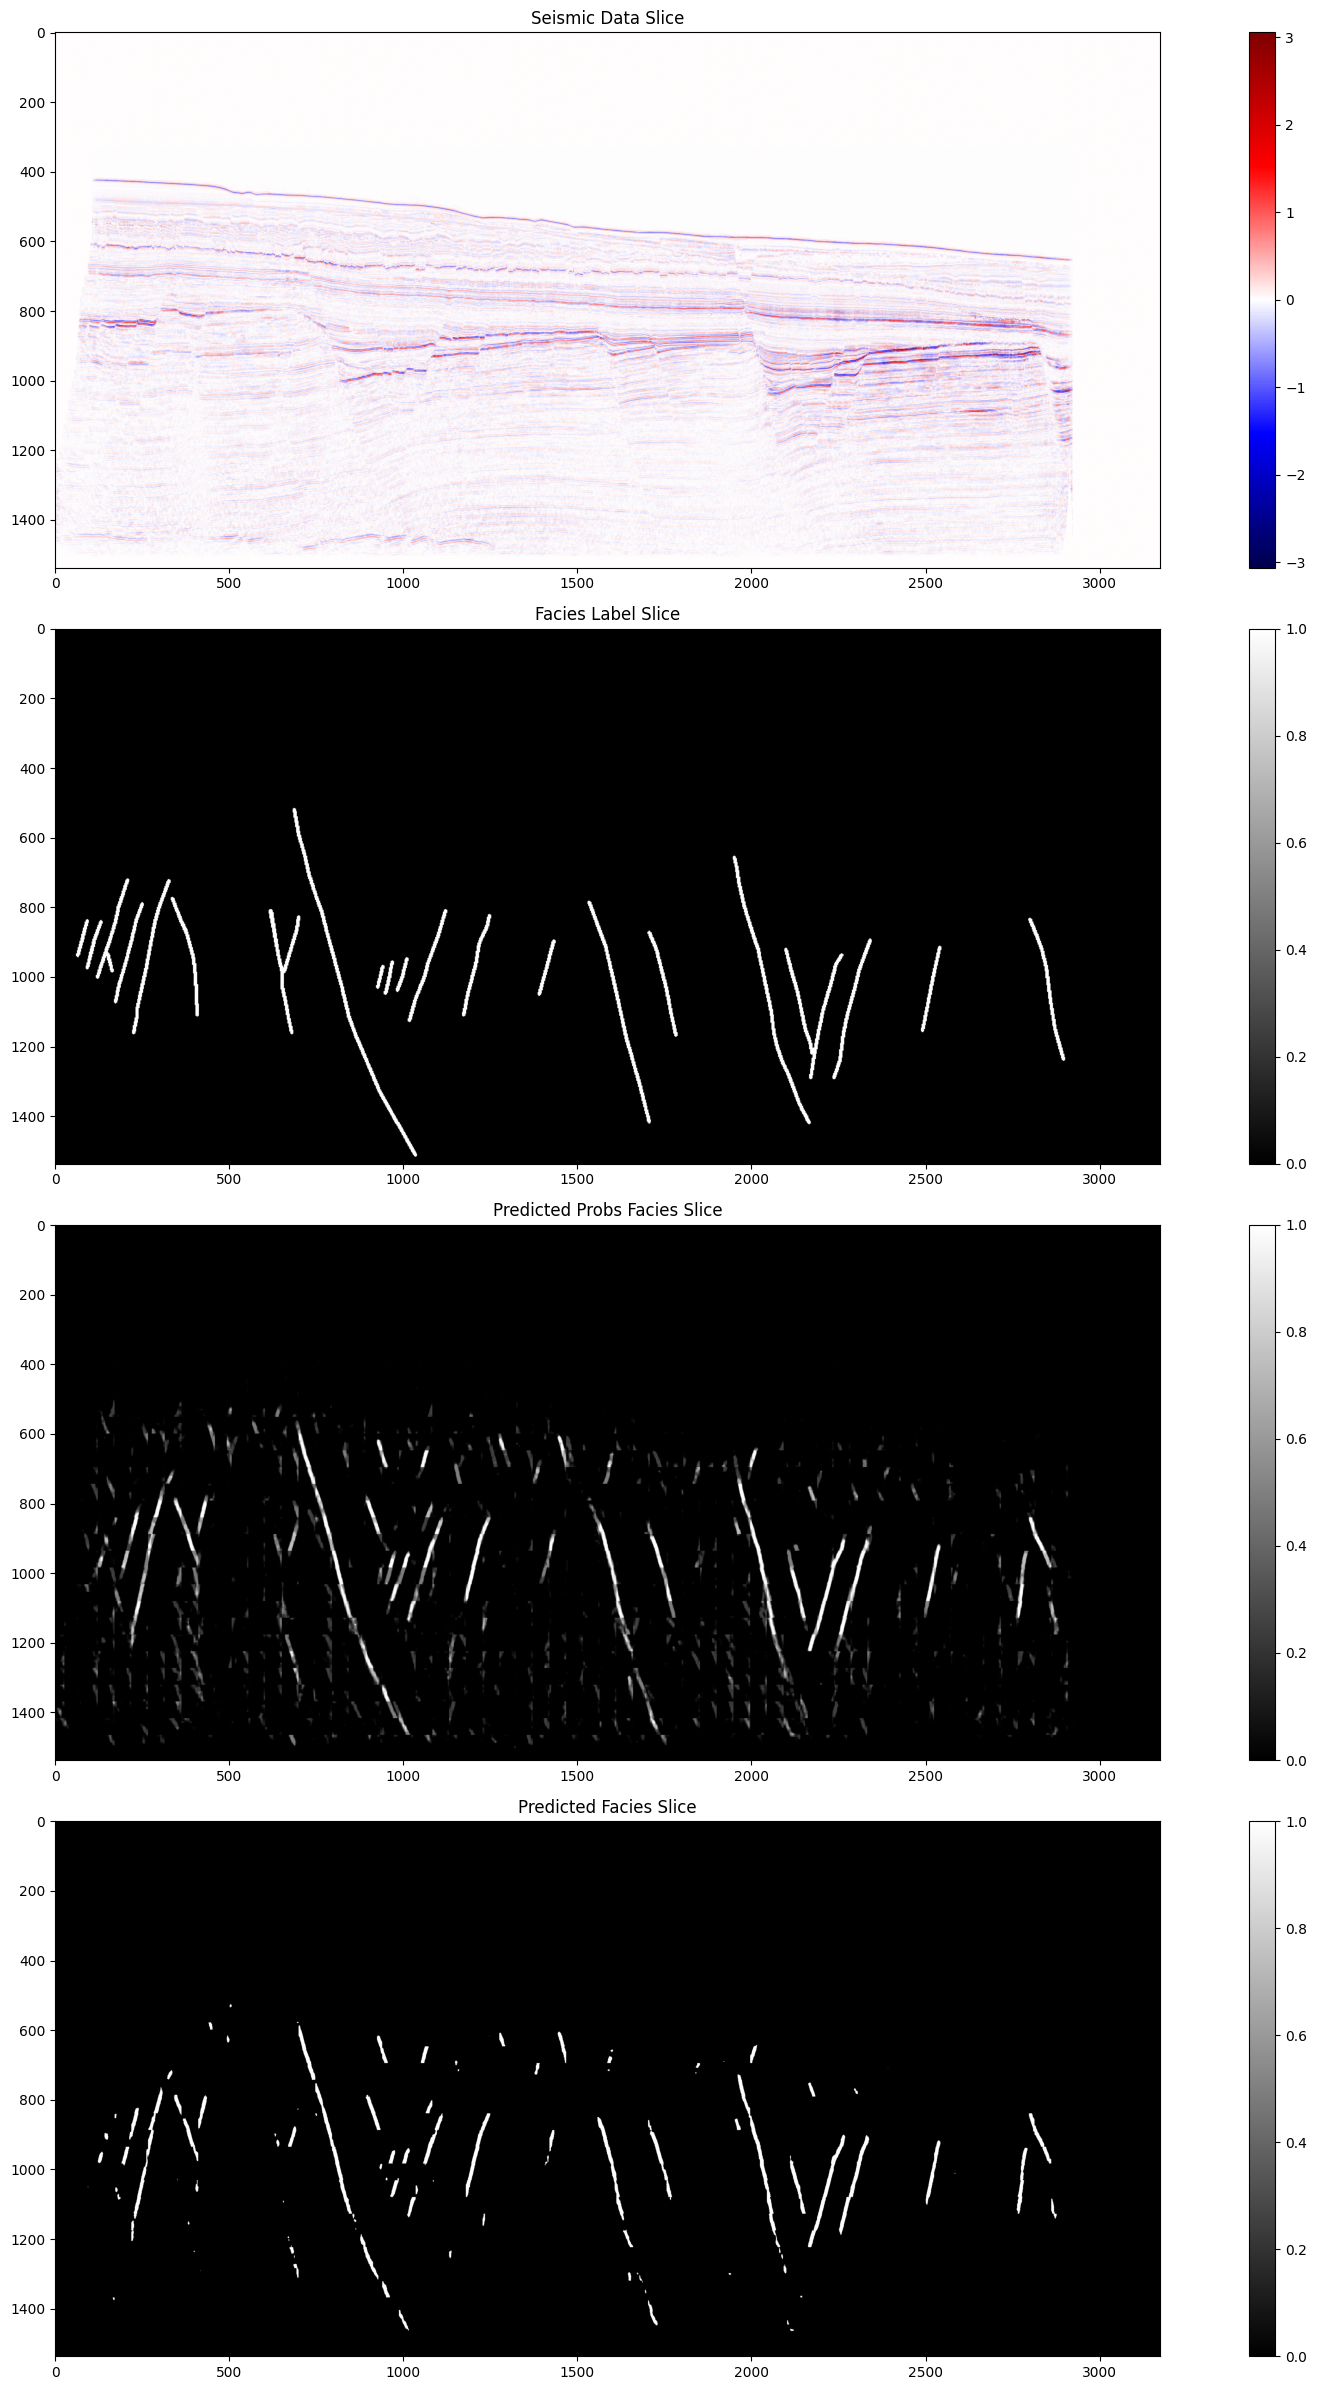

In [84]:
# Result with 100 epochs, batch_size 512, norm "min-max"
index = 10
data = inputs[index].cpu().numpy()
label = y_true[index].cpu().numpy()  # type: ignore
prediction = preds[index].cpu().numpy()

fig = plot_data_label_prediction_slice(
    data=data,
    label=label,
    prediction=prediction,
    size=(18, 24),
)
fig.show()